# Experiment: ScoNet-MT

My notes for experiment **ScoNet-MT** from the Scoliosis1K paper (Zhou et al., MICCAI 2024, arXiv 2407.05726), Table 4.
This one is ScoNet + a triplet loss where the positives are **copies of the same child** (subject id): classification + gait recognition at the same time. This is the final model of the paper and the same thing as `configs/sconet/sconet_scoliosis1k.yaml`.

The 6 experiments of Table 4 (paper numbers on the full 1:1:8 test set):

| # | experiment | after the backbone | loss | triplet positives are | paper acc / sens / spec |
|---|---|---|---|---|---|
| 1 | CNN | 1 global bin + FC + linear classifier | CE | - | 45.5 / 99.0 / 27.0 |
| 2 | CNN-Triplet | 1 global bin + FC + linear classifier | CE + triplet | same class | 56.3 / 77.0 / 85.0 |
| 3 | CNN-MT | 1 global bin + FC + linear classifier | CE + triplet | same child | 57.8 / 96.1 / 44.4 |
| 4 | ScoNet | 16 strips + SeparateFCs + BNNeck | CE | - | 51.3 / 100.0 / 33.2 |
| 5 | ScoNet-Triplet | 16 strips + SeparateFCs + BNNeck | CE + triplet | same class | 61.2 / 100.0 / 46.6 |
| 6 | **ScoNet-MT** (this one) | 16 strips + SeparateFCs + BNNeck | CE + triplet | same child | 82.0 / 99.0 / 76.5 |

How I read the paper for the 6 (section 4, ablation):
- **CNN**: cross entropy only, **no** horizontal pooling and **no** BNNeck. So: one vector for the whole body and a normal linear classifier.
- **ScoNet**: horizontal pooling into 16 strips, a fully connected layer into the metric space, BNNeck before the classifier.
- **-Triplet**: the same network + a triplet loss. The paper doesn't say what the positives are, but the -MT version is the one that uses identity, so here the positives must be the **class**.
- **-MT**: the triplet loss is used for gait recognition (who is walking). The paper says the positive is the same gait sequence as the anchor, just made of different frames. Total loss = cross entropy + triplet, no weights.

Every notebook in `self_learning/` is written out completely, nothing is imported from `opengait` or from the other experiment folders. So I can read one experiment from top to bottom without jumping around. The parts that are the same in all 6 (loading, transform, batch, ResNet9, optimizer, training loop, evaluation) are written exactly the same in every notebook, so the **only** differences between the experiments are the head and the loss.

Code follows:
- `opengait/data/transform.py`, `sampler.py` (loading and batches)
- `opengait/modeling/backbones/resnet.py`, `modules.py`, `models/sconet.py` (the network)
- `opengait/modeling/losses/triplet.py`, `ce.py` (the loss)
- `opengait/evaluation/evaluator.py` (evaluation)
- settings from `configs/sconet/sconet_scoliosis1k.yaml` and section 4 of the paper

**Version 2.** My first version got exactly 33.3% in every experiment. The CNN ones broke during training (loss `nan`, every child predicted "neutral") and the ScoNet ones just memorised the 12 training children. What I changed:
- lr 0.001 instead of 0.1 in all 6 (why: see part 1)
- training stops with an error if the loss becomes `nan` / `inf`, so a broken run can't finish quietly anymore
- CNN head: the FC and the classifier have no bias, like OpenGait's `SeparateFCs` and the classifier weights in `SeparateBNNecks` (both are only a weight matrix)
- the evaluation code is now exactly the same in all 6 (the strip figure only shows up when there are 16 strips)

Important: I train on a **small subset** (12 children), not the full 744. This notebook is for understanding how ScoNet-MT works and how it differs from the other 5. The numbers at the end can not be compared with the paper.

Run the cells from top to bottom. Kernel: sconet (Python 3.10).

## 1 - Setup
Settings from the paper and the config:
- 30 frames per sequence in training, input 64 x 44
- SGD, momentum 0.9, weight decay 5e-4, lr x 0.1 at 50%, 70%, 90% of training (paper: 10000, 14000, 18000 of 20000)
- fp16 (mixed precision), like `enable_float16: true`
- triplet margin 0.2
- cross entropy with label smoothing 0.1, scale 16 (`loss_cfg`, only needed because the BNNeck logits are cosines, see part 8)

What is different from the paper:
- **lr 0.001 instead of 0.1.** With 0.1 my three CNN notebooks broke in the first iterations: the weights blew up, the logits got to about ±68000 (more than the fp16 maximum 65504, so they became `inf`), the loss became `nan`, and after that every child was predicted "neutral" = 4 / 12 = 33.3%. I tried a few values on the CNN baseline (same seed):

  | lr | what happened |
  |---|---|
  | 0.1 (paper), fp16 | loss `nan` at iteration 3 |
  | 0.1, fp32 | loss `nan` at iteration 7, so it is not only an fp16 problem |
  | 0.019 (= 0.1 x 12 / 64, scaled to my batch size) | loss jumps between 60 and 340, `nan` at iteration 56 |
  | 0.01 | no `nan`, but CNN and CNN-Triplet **die**: by iteration 31 all 512 channels after global pooling are 0 (dead ReLU), every child gets the same output 0.33 / 0.33 / 0.33 |
  | **0.001** | stable, no dead channels, batch accuracy goes up to 1.0 |

  Why the CNN is so fragile: at the start the global feature (mean + max over the whole map, after a max over 30 frames) has a length of about **166**, so the first gradient is about **420**. Big steps push the logits to ±1000, and the network "fixes" that by switching its ReLUs off for good. ScoNet doesn't have this problem because its BNNeck normalises the features before the classifier. The CNN baseline has no BNNeck (the paper removes it on purpose), so nothing keeps it small. OpenGait has no gradient clipping or warmup either, so the learning rate is the only knob from the paper's recipe I can turn.

  The paper's 0.1 is for a batch of 64 sequences (`batch_size: [8, 8]`), mine is 12. I use 0.001 in **all 6** notebooks, so the only differences between them are still the head and the loss. (With 0.01 the ScoNet notebooks trained fine, but then the comparison would not be fair.)
- 4 children per class for training (12), 4 other children per class for testing (12). The real 1:1:8 split has 744 / 749.
- batch: 2 children per class x 2 copies = 12 sequences (the config uses 8 x 8 = 64). 24 x 30 frames does not fit in my 4 GB GPU.
- 300 iterations instead of 20000, with the lr drops at the same relative points (150, 210, 270)

`SEED` is the same in all 6 notebooks, so all 6 experiments use the same children.

In [1]:
import os
import json
import pickle
import random
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

EXPERIMENT = "sconet_mt"
OPENGAIT = r"C:\Users\ASUS\.vscode\OpenGait"
PKL_ROOT = os.path.join(OPENGAIT, "datasets", "Scoliosis1K", "Scoliosis1K-sil-pkl")
SPLIT_JSON = os.path.join(OPENGAIT, "datasets", "Scoliosis1K", "Scoliosis1K_118.json")
OUT_ROOT = os.path.join(OPENGAIT, "self_learning", EXPERIMENT, "output")
FIG_DIR = os.path.join(OUT_ROOT, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

LABELS = {"negative": 0, "neutral": 1, "positive": 2}
LABEL_NAMES = ["negative", "neutral", "positive"]

N_TRAIN_PER_CLASS = 4
N_TEST_PER_CLASS = 4
FRAMES_TRAIN = 30
P_PER_CLASS = 2
K = 2
TEST_FRAME_LIMIT = 720

LR = 0.001
MOMENTUM = 0.9
WEIGHT_DECAY = 5e-4
TOTAL_ITER = 300
MILESTONES = [150, 210, 270]
GAMMA = 0.1
USE_FP16 = DEVICE == "cuda"

TRIPLET_MARGIN = 0.2
CE_SCALE = 16
LABEL_SMOOTH = 0.1


def save_and_show(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, name), dpi=120)
    plt.show()


print("experiment:", EXPERIMENT)
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")
print("torch:", torch.__version__)

experiment: sconet_mt
device: cuda NVIDIA GeForce RTX 3050 Laptop GPU
torch: 2.5.1+cu121


### My result
Runs on the GPU (RTX 3050 Laptop, torch 2.5.1+cu121), so fp16 is on.

## 2 - Choose the children from the 1:1:8 split
`Scoliosis1K_118.json` has a `TRAIN_SET` and a `TEST_SET` (subject ids). The class of a child is the folder name inside its subject folder: `<subject>/<class>/<view>/<view>.pkl`.

In the 1:1:8 split the training set is mostly negative (about 596 negative, 74 neutral, 74 positive). I take the **same number per class** (4) so that 3 x 4 = 12 children are enough to learn something about every class.
- training children come only from `TRAIN_SET`, test children only from `TEST_SET`, so the test children are really never seen
- the pick is random but fixed with `SEED`, the same 24 children in all 6 experiments

In [2]:
with open(SPLIT_JSON) as f:
    split = json.load(f)


def subject_class(subject):
    return os.listdir(os.path.join(PKL_ROOT, subject))[0]


def pick_subjects(subjects, n_per_class, seed=SEED):
    by_class = {c: [] for c in LABEL_NAMES}
    for s in sorted(subjects):
        by_class[subject_class(s)].append(s)
    rng = random.Random(seed)
    picked = {c: sorted(rng.sample(by_class[c], n_per_class)) for c in LABEL_NAMES}
    return picked, {c: len(v) for c, v in by_class.items()}


train_pick, train_count = pick_subjects(split["TRAIN_SET"], N_TRAIN_PER_CLASS)
test_pick, test_count = pick_subjects(split["TEST_SET"], N_TEST_PER_CLASS)
print("full TRAIN_SET per class:", train_count)
print("full TEST_SET  per class:", test_count)
print("my train children:", train_pick)
print("my test children :", test_pick)

full TRAIN_SET per class: {'negative': 596, 'neutral': 74, 'positive': 74}
full TEST_SET  per class: {'negative': 204, 'neutral': 126, 'positive': 419}
my train children: {'negative': ['00546', '00839', '01015', '01068'], 'neutral': ['01409', '01437', '01468', '01473'], 'positive': ['00221', '00332', '00422', '00429']}
my test children : {'negative': ['00536', '00914', '00937', '01243'], 'neutral': ['01340', '01384', '01387', '01486'], 'positive': ['00172', '00237', '00282', '00473']}


### My result
The 1:1:8 split is really unbalanced: `TRAIN_SET` has 596 / 74 / 74 and `TEST_SET` 204 / 126 / 419 (negative / neutral / positive). I take 4 of each class from both, so my train set and my test set are balanced 4 / 4 / 4. The same 24 children in all 6 notebooks (same seed).

## 3 - Load the .pkl files
Every item gets two numbers:
- `pid` (person id): 0 to 11, one per child. The triplet loss of the -MT experiments uses it.
- `label` (class): negative 0, neutral 1, positive 2. Same mapping as OpenGait `sconet.py`. Cross entropy uses it, and the triplet loss of the -Triplet experiments too.

Every `seq` is `(frames, 64, 64)`, uint8, 0-255. Every child has only one sequence (view `000_180`).

train | negative | subject 00546 | pid  0 | label 0 | (300, 64, 64)
train | negative | subject 00839 | pid  1 | label 0 | (300, 64, 64)
train | negative | subject 01015 | pid  2 | label 0 | (300, 64, 64)
train | negative | subject 01068 | pid  3 | label 0 | (300, 64, 64)
train |  neutral | subject 01409 | pid  4 | label 1 | (300, 64, 64)
train |  neutral | subject 01437 | pid  5 | label 1 | (300, 64, 64)
train |  neutral | subject 01468 | pid  6 | label 1 | (300, 64, 64)
train |  neutral | subject 01473 | pid  7 | label 1 | (300, 64, 64)
train | positive | subject 00221 | pid  8 | label 2 | (300, 64, 64)
train | positive | subject 00332 | pid  9 | label 2 | (300, 64, 64)
train | positive | subject 00422 | pid 10 | label 2 | (300, 64, 64)
train | positive | subject 00429 | pid 11 | label 2 | (300, 64, 64)
test  | negative | subject 00536 | label 0 | (300, 64, 64)
test  | negative | subject 00914 | label 0 | (300, 64, 64)
test  | negative | subject 00937 | label 0 | (300, 64, 64)
test  |

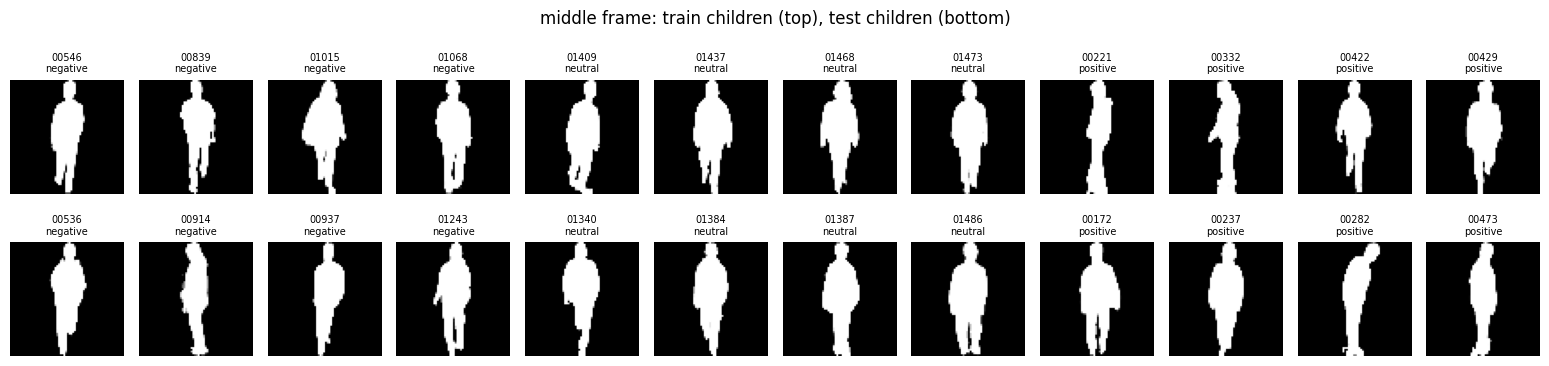

In [3]:
def load_pkl(subject, cls):
    folder = os.path.join(PKL_ROOT, subject, cls)
    view = os.listdir(folder)[0]
    with open(os.path.join(folder, view, f"{view}.pkl"), "rb") as f:
        return pickle.load(f)


def load_items(picked):
    items = []
    for cls in LABEL_NAMES:
        for subject in picked[cls]:
            items.append({"subject": subject, "class": cls, "pid": len(items),
                          "label": LABELS[cls], "seq": load_pkl(subject, cls)})
    return items


train_data = load_items(train_pick)
test_data = load_items(test_pick)
for item in train_data:
    print(f"train | {item['class']:>8} | subject {item['subject']} | pid {item['pid']:2d} | label {item['label']} | {item['seq'].shape}")
for item in test_data:
    print(f"test  | {item['class']:>8} | subject {item['subject']} | label {item['label']} | {item['seq'].shape}")

fig, ax = plt.subplots(2, len(train_data), figsize=(1.3 * len(train_data), 4))
for i, item in enumerate(train_data):
    mid = len(item["seq"]) // 2
    ax[0, i].imshow(item["seq"][mid], cmap="gray")
    ax[0, i].set_title(f"{item['subject']}\n{item['class']}", fontsize=7)
    ax[1, i].imshow(test_data[i]["seq"][len(test_data[i]["seq"]) // 2], cmap="gray")
    ax[1, i].set_title(f"{test_data[i]['subject']}\n{test_data[i]['class']}", fontsize=7)
for a in ax.flat:
    a.axis("off")
fig.suptitle("middle frame: train children (top), test children (bottom)")
save_and_show(fig, "03_children.png")

### My result
All 24 sequences are `(300, 64, 64)`, so every child has exactly 300 frames. pid 0-3 are negative, 4-7 neutral, 8-11 positive. In the picture all the silhouettes look alike to me, I can't see the scoliosis by eye at all.

## 4 - Transform and frame sampling
`BaseSilCuttingTransform`: cut 10 columns on each side (64 x 64 becomes 64 x 44) and divide by 255.

Training (`fixed_unordered`): 30 random frames, a new draw every time the sequence is used.
Testing (`all_ordered`): all frames in order, at most 720.

In [4]:
def sil_transform(seq):
    cut = int(seq.shape[-1] // 64) * 10
    return seq[..., cut:-cut] / 255.0


def sample_train_frames(seq, n=FRAMES_TRAIN):
    idx = np.random.choice(len(seq), n, replace=len(seq) < n)
    return seq[idx], idx


def all_test_frames(seq, limit=TEST_FRAME_LIMIT):
    return seq[:limit]


x = sil_transform(train_data[0]["seq"])
print("before:", train_data[0]["seq"].shape, train_data[0]["seq"].dtype, "| after:", x.shape, x.dtype, "max", x.max())

before: (300, 64, 64) uint8 | after: (300, 64, 44) float64 max 1.0


### My result
`(300, 64, 64)` uint8 becomes `(300, 64, 44)` float with max 1.0, so the cut and the / 255 work.

## 5 - Making a training batch
OpenGait's `TripletSampler` picks P random subjects and K sequences of each. I changed it a little: I pick **2 children of every class**, then K = 2 copies of each child (every copy has different random frames). That is 3 x 2 x 2 = 12 sequences.

Why per class:
- the triplet loss code (OpenGait `TripletLoss`) needs every anchor to have the same number of positives. With class labels as positives that only works when every class has the same number of items in the batch.
- I use exactly the same batch in all 6 experiments, also in the ones without triplet loss, so the comparison is fair: only the head and the loss change.

Batch shape: `[12, 30, 64, 44]`.

In [5]:
def make_train_batch(items, p_per_class=P_PER_CLASS, k=K):
    seqs, pids, labels = [], [], []
    for cls in LABEL_NAMES:
        pool = [item for item in items if item["class"] == cls]
        for item in random.sample(pool, p_per_class):
            for _ in range(k):
                frames, _ = sample_train_frames(item["seq"])
                seqs.append(sil_transform(frames))
                pids.append(item["pid"])
                labels.append(item["label"])
    order = list(range(len(seqs)))
    random.shuffle(order)
    sils = torch.tensor(np.stack([seqs[i] for i in order]), dtype=torch.float32)
    pids = torch.tensor([pids[i] for i in order])
    labels = torch.tensor([labels[i] for i in order])
    return sils, pids, labels


sils, pids, labels = make_train_batch(train_data)
print("sils  :", tuple(sils.shape), sils.dtype)
print("pids  :", pids.tolist())
print("labels:", labels.tolist())

sils  : (12, 30, 64, 44) torch.float32
pids  : [11, 9, 11, 5, 3, 3, 9, 1, 1, 4, 5, 4]
labels: [2, 2, 2, 1, 0, 0, 2, 0, 0, 1, 1, 1]


### My result
Shape `[12, 30, 64, 44]`. Every pid is in there exactly 2 times (the 2 copies) and every class 4 times. pids and labels are shuffled together, so they still belong to the same sequence.

## 6 - The backbone: ResNet9 (same in all 6 experiments)
Same as `ResNet9` in OpenGait with the config `channels [64, 128, 256, 512]`, `layers [1, 1, 1, 1]`, `strides [1, 2, 2, 1]`, `maxpool: false`:
- `BasicBlock` (torchvision): conv 3x3, BN, relu, conv 3x3, BN, add the input back (skip connection), relu. A 1x1 conv + BN on the input if the size or channels change.
- first conv 3x3 1 to 64 channels + BN + relu, no max pool, then 4 blocks with 64, 128, 256, 512 channels and strides 1, 2, 2, 1.
- every frame goes through on its own: `[n, s, 64, 44]` is reshaped to `[n * s, 1, 64, 44]` (`SetBlockWrapper` in OpenGait).

Then **temporal pooling** (`PackSequenceWrapper(torch.max)`): the max over all frames, `[n, s, 512, 16, 11]` becomes `[n, 512, 16, 11]`. The order of the frames does not matter.

`init_parameters` is copied from OpenGait's `BaseModel`: xavier for conv and linear, BN weight around 1.

In [6]:
class BasicBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.downsample = None
        if stride != 1 or in_ch != out_ch:
            self.downsample = nn.Sequential(nn.Conv2d(in_ch, out_ch, 1, stride, bias=False), nn.BatchNorm2d(out_ch))

    def forward(self, x):
        identity = x if self.downsample is None else self.downsample(x)
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return self.relu(out + identity)


class ResNet9(nn.Module):
    def __init__(self, channels=(64, 128, 256, 512), strides=(1, 2, 2, 1)):
        super().__init__()
        self.conv1 = nn.Conv2d(1, channels[0], 3, 1, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(channels[0])
        self.relu = nn.ReLU(inplace=True)
        self.layer1 = BasicBlock(channels[0], channels[0], strides[0])
        self.layer2 = BasicBlock(channels[0], channels[1], strides[1])
        self.layer3 = BasicBlock(channels[1], channels[2], strides[2])
        self.layer4 = BasicBlock(channels[2], channels[3], strides[3])

    def forward(self, x):
        x = self.relu(self.bn1(self.conv1(x)))
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        return self.layer4(x)


def temporal_max(x, n, s):
    x = x.reshape(n, s, *x.shape[1:])
    return x.max(dim=1)[0]


def init_parameters(model):
    for m in model.modules():
        if isinstance(m, (nn.Conv2d, nn.Linear)):
            nn.init.xavier_uniform_(m.weight)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, (nn.BatchNorm2d, nn.BatchNorm1d)):
            nn.init.normal_(m.weight, 1.0, 0.02)
            nn.init.zeros_(m.bias)

## 7 - The head of ScoNet
Same as `models/sconet.py` with the config (`bin_num: [16]`, `SeparateFCs 512 -> 256, 16 parts`, `SeparateBNNecks 256 -> 3, 16 parts`). After temporal pooling:
- **horizontal pooling** (`bin_num: [16]`): the 16 rows become 16 body strips (head ... feet), mean + max over the 11 columns. `[n, 512, 16, 11]` becomes `[n, 512, 16]`.
- **SeparateFCs**: every strip has its own linear layer 512 to 256. Output `[n, 256, 16]` is the **embedding** (`embed_1` in `sconet.py`, the triplet loss uses this).
- **SeparateBNNecks**: batch norm over all 256 x 16 numbers, then every strip vector is normalised to length 1 and multiplied with the normalised class weights. That is a cosine similarity between -1 and 1 for every class in every strip. Output `[n, 3, 16]` are the **logits**.

This is the difference with the CNN baseline: 16 strips instead of 1 global vector, and BNNeck cosine logits instead of a normal linear classifier. Because the logits are cosines, they can never be bigger than 1.

In [7]:
def horizontal_pooling(x, bins=16):
    n, c = x.shape[:2]
    z = x.view(n, c, bins, -1)
    return z.mean(-1) + z.max(-1)[0]


class SeparateFCs(nn.Module):
    def __init__(self, parts, in_ch, out_ch):
        super().__init__()
        self.fc_bin = nn.Parameter(nn.init.xavier_uniform_(torch.zeros(parts, in_ch, out_ch)))

    def forward(self, x):
        x = x.permute(2, 0, 1)
        out = x.matmul(self.fc_bin)
        return out.permute(1, 2, 0).contiguous()


class SeparateBNNecks(nn.Module):
    def __init__(self, parts, in_ch, class_num):
        super().__init__()
        self.fc_bin = nn.Parameter(nn.init.xavier_uniform_(torch.zeros(parts, in_ch, class_num)))
        self.bn1d = nn.BatchNorm1d(in_ch * parts)

    def forward(self, x):
        n, c, p = x.shape
        x = self.bn1d(x.reshape(n, -1)).reshape(n, c, p)
        feature = F.normalize(x.permute(2, 0, 1), dim=-1)
        logits = feature.matmul(F.normalize(self.fc_bin, dim=1))
        return feature.permute(1, 2, 0).contiguous(), logits.permute(1, 2, 0).contiguous()


class ScoNet(nn.Module):
    def __init__(self, num_classes=3, parts=16, embed_dim=256):
        super().__init__()
        self.parts = parts
        self.backbone = ResNet9()
        self.fcs = SeparateFCs(parts, 512, embed_dim)
        self.bnnecks = SeparateBNNecks(parts, embed_dim, num_classes)
        init_parameters(self)

    def forward(self, sils):
        n, s, h, w = sils.shape
        x = self.backbone(sils.reshape(n * s, 1, h, w))
        x = temporal_max(x, n, s)
        feat = horizontal_pooling(x, self.parts)
        embed = self.fcs(feat)
        _, logits = self.bnnecks(embed)
        return embed, logits


def trace_shapes(model, sils):
    n, s, h, w = sils.shape
    with torch.no_grad():
        x = model.backbone(sils.reshape(n * s, 1, h, w))
        print("backbone per frame   :", tuple(x.shape))
        x = temporal_max(x, n, s)
        print("max over frames      :", tuple(x.shape))
        x = horizontal_pooling(x, model.parts)
        print("16 strips            :", tuple(x.shape))
        e = model.fcs(x)
        print("embedding (SepFCs)   :", tuple(e.shape))
        print("logits (BNNeck)      :", tuple(model.bnnecks(e)[1].shape))


Model = ScoNet
model = Model().to(DEVICE).eval()
print(f"parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.2f} million")
trace_shapes(model, sils[:2].to(DEVICE))

parameters: 7.01 million


backbone per frame   : (60, 512, 16, 11)
max over frames      : (2, 512, 16, 11)
16 strips            : (2, 512, 16)
embedding (SepFCs)   : (2, 256, 16)
logits (BNNeck)      : (2, 3, 16)


### My result
7.01 million parameters, 2 million more than the CNN, because SeparateFCs has its own 512 x 256 matrix for every one of the 16 strips. Shapes: `(60, 512, 16, 11)` per frame -> `(2, 512, 16, 11)` after the max over frames -> `(2, 512, 16)` strips -> `(2, 256, 16)` embedding -> `(2, 3, 16)` logits, a score per class per strip.

## 8 - The loss: cross entropy + triplet (positives = same child)
`total loss = 1.0 x triplet + 1.0 x cross entropy` (`loss_cfg` in the config).

**Triplet loss** (margin 0.2) on the embedding, using `pid` (child):
- positives are the copies of the **same child**, negatives are all other children, even other children of the same class. This is gait recognition (who is walking?), the second task of multi-task learning. The paper's positive is "the same sequence, different frames": every child here has one sequence, and my K = 2 copies have different random frames, so that is exactly it.
- for every anchor a, positive p, negative n: `max(0, d(a,p) - d(a,n) + 0.2)`, euclidean distance
- average only over the triplets that are not 0 (`AvgNonZeroReducer`), done per part then averaged
- with 12 items: every anchor has 2 positives (its own 2 copies, itself included) and 10 negatives. A neutral child counts as negative for another neutral child here!

**Cross entropy** (label smoothing 0.1), on the logits, using `label`:
- logits are cosines between -1 and 1, times 16 makes the softmax sharp enough to learn
- done for every one of the 16 strips with the same label, then averaged
- label smoothing 0.1: the target is 93.3% for the right class and 3.3% for each other one, so the model doesn't get overconfident

The figure shows the distances between the 12 batch items before training, sorted by class and child.

triplet 0.1912 (non-zero triplets per part 240) | ce 1.4820 | acc 0.318
logits: min -0.195 max 0.169


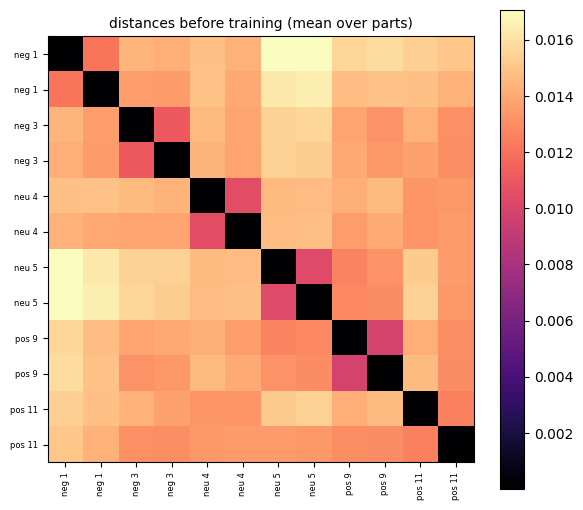

In [8]:
def triplet_loss(embed, ids, margin=TRIPLET_MARGIN):
    x = embed.permute(2, 0, 1).float()
    x2 = (x ** 2).sum(-1)
    dist = torch.sqrt(F.relu(x2.unsqueeze(2) + x2.unsqueeze(1) - 2 * x.matmul(x.transpose(1, 2))))
    same = ids.unsqueeze(1) == ids.unsqueeze(0)
    p, n, _ = dist.shape
    ap = dist[:, same].view(p, n, -1, 1)
    an = dist[:, ~same].view(p, n, 1, -1)
    loss = F.relu(ap - an + margin).view(p, -1)
    num = (loss != 0).sum(-1).float()
    avg = loss.sum(-1) / (num + 1e-9)
    avg[num == 0] = 0
    return avg.mean(), num.mean(), dist

def ce_loss(logits, labels, scale=CE_SCALE, eps=LABEL_SMOOTH):
    n, c, p = logits.shape
    loss = F.cross_entropy(logits.float() * scale, labels.unsqueeze(1).repeat(1, p), label_smoothing=eps)
    acc = (logits.argmax(1) == labels.unsqueeze(1)).float().mean()
    return loss, acc


def show_distances(dist, pids, labels, name, title):
    order = torch.argsort(labels.cpu() * 100 + pids.cpu())
    d = dist.mean(0).detach().float().cpu()[order][:, order]
    ticks = [f"{LABEL_NAMES[l][:3]} {p}" for p, l in zip(pids.cpu()[order].tolist(), labels.cpu()[order].tolist())]
    fig, ax = plt.subplots(figsize=(6, 5.3))
    im = ax.imshow(d, cmap="magma")
    ax.set_xticks(range(len(ticks)), ticks, rotation=90, fontsize=6)
    ax.set_yticks(range(len(ticks)), ticks, fontsize=6)
    ax.set_title(title, fontsize=10)
    fig.colorbar(im)
    save_and_show(fig, name)


pids_d, labels_d = pids.to(DEVICE), labels.to(DEVICE)
with torch.no_grad():
    embed, logits = model(sils.to(DEVICE))
    l_tri, n_tri, dist = triplet_loss(embed, pids_d)
    l_ce, acc = ce_loss(logits, labels_d)
print(f"triplet {l_tri.item():.4f} (non-zero triplets per part {n_tri.item():.0f}) | ce {l_ce.item():.4f} | acc {acc.item():.3f}")
print(f"logits: min {logits.min().item():.3f} max {logits.max().item():.3f}")
show_distances(dist, pids, labels, "08_distances_before.png", "distances before training (mean over parts)")

### My result
Before training: triplet 0.191 with 240 non-zero triplets per part (all of them), ce 1.482, acc 0.318.

## 9 - Optimizer and learning rate (same in all 6 experiments)
- SGD, **lr 0.001** (paper 0.1, why: part 1), momentum 0.9, weight decay 5e-4
- MultiStepLR: lr x 0.1 at iteration 150, 210, 270
- fp16 with `GradScaler`; if the gradients overflow, that step is skipped and does not count as an iteration (like OpenGait)

I make a **new** model here, so training starts from fresh random weights.

In [9]:
torch.manual_seed(SEED)
model = Model().to(DEVICE)
optimizer = torch.optim.SGD(model.parameters(), lr=LR, momentum=MOMENTUM, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=MILESTONES, gamma=GAMMA)
scaler = torch.amp.GradScaler("cuda", enabled=USE_FP16)
print(model.__class__.__name__, "| lr plan:", [round(LR * GAMMA ** i, 8) for i in range(len(MILESTONES) + 1)])

ScoNet | lr plan: [0.001, 0.0001, 1e-05, 1e-06]


## 10 - Training
One iteration: new batch, forward, loss = triplet on child + cross entropy, backward, SGD step, scheduler step.
`model.train()`: batch norm uses the statistics of the current batch.

New in version 2: if the loss becomes `nan` or `inf`, the cell stops with an error. In version 1 the CNN loss was `nan` from iteration ~3 and the loop still ran all 300 iterations with a frozen, broken model.

`skipped` counts the fp16 steps where the gradients overflowed (normal at the start while `GradScaler` finds its scale).

In [10]:
history = {key: [] for key in ["loss", "triplet", "ce", "acc", "lr"]}
model.train()
it = 0
skipped = 0
t0 = time.time()
while it < TOTAL_ITER:
    sils, pids, labels = make_train_batch(train_data)
    sils, pids, labels = sils.to(DEVICE), pids.to(DEVICE), labels.to(DEVICE)

    with torch.autocast(device_type=DEVICE, enabled=USE_FP16):
        embed, logits = model(sils)
    l_ce, acc = ce_loss(logits, labels)
    l_tri, n_tri, _ = triplet_loss(embed, pids)
    loss = l_tri + l_ce
    if not torch.isfinite(loss):
        raise RuntimeError(f"loss became {loss.item()} at iteration {it}, training broke")

    optimizer.zero_grad()
    scaler.scale(loss).backward()
    scale_before = scaler.get_scale()
    scaler.step(optimizer)
    scaler.update()
    if scale_before > scaler.get_scale():
        skipped += 1
        continue
    it += 1
    scheduler.step()

    history["loss"].append(loss.item())
    history["triplet"].append(l_tri.item())
    history["ce"].append(l_ce.item())
    history["acc"].append(acc.item())
    history["lr"].append(optimizer.param_groups[0]["lr"])
    if it % 25 == 0:
        print(f"iter {it:4d} | loss {loss.item():.4f} | triplet {l_tri.item():.4f} | ce {l_ce.item():.4f} "
              f"| acc {acc.item():.3f} | lr {history['lr'][-1]:.4g} | skipped {skipped} | {time.time() - t0:.0f}s")

iter   25 | loss 0.5957 | triplet 0.1027 | ce 0.4930 | acc 0.906 | lr 0.001 | skipped 2 | 12s


iter   50 | loss 0.5011 | triplet 0.0963 | ce 0.4048 | acc 0.990 | lr 0.001 | skipped 2 | 24s


iter   75 | loss 0.4712 | triplet 0.0788 | ce 0.3923 | acc 0.990 | lr 0.001 | skipped 2 | 35s


iter  100 | loss 0.4378 | triplet 0.0572 | ce 0.3806 | acc 0.990 | lr 0.001 | skipped 2 | 46s


iter  125 | loss 0.4316 | triplet 0.0491 | ce 0.3825 | acc 0.990 | lr 0.001 | skipped 2 | 57s


iter  150 | loss 0.4563 | triplet 0.0871 | ce 0.3691 | acc 0.990 | lr 0.0001 | skipped 2 | 68s


... (2 outputs left out)

iter  225 | loss 0.3700 | triplet 0.0226 | ce 0.3474 | acc 0.995 | lr 1e-05 | skipped 2 | 101s


iter  250 | loss 0.4072 | triplet 0.0589 | ce 0.3483 | acc 0.995 | lr 1e-05 | skipped 2 | 112s


iter  275 | loss 0.3820 | triplet 0.0288 | ce 0.3532 | acc 0.995 | lr 1e-06 | skipped 2 | 123s


iter  300 | loss 0.3710 | triplet 0.0132 | ce 0.3578 | acc 0.995 | lr 1e-06 | skipped 2 | 135s


### My result
Fast start again (acc 0.99 at iteration 50). The triplet goes from 0.10 down to 0.013 at the end, so the copies of the same child really end up close. ce 0.36.

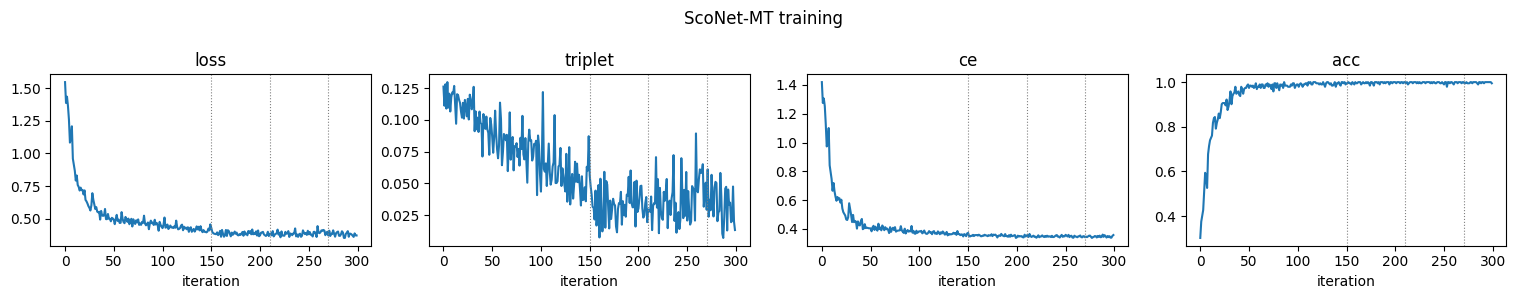

In [11]:
plot_keys = [key for key in history if key != "lr"]
fig, ax = plt.subplots(1, len(plot_keys), figsize=(3.8 * len(plot_keys), 3))
for a, key in zip(ax, plot_keys):
    a.plot(history[key])
    for m in MILESTONES:
        a.axvline(m, color="gray", ls=":", lw=0.8)
    a.set_title(key)
    a.set_xlabel("iteration")
fig.suptitle("ScoNet-MT training")
save_and_show(fig, "10_training_curves.png")

### My result
Smooth, the triplet keeps going down after the first lr drop too. After the first lr drop (iteration 150, lr 0.0001 and lower) the curves are basically flat: with my 300 iterations, the second half of training hardly changes the model anymore.

### After training: distances again
A new batch with the trained model. The 2 copies of the same child should now be close (small dark 2 x 2 blocks per child).

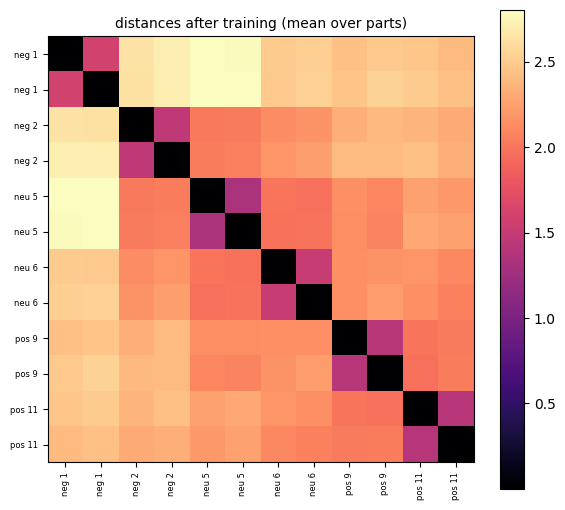

In [12]:
model.eval()
sils_b, pids_b, labels_b = make_train_batch(train_data)
with torch.no_grad():
    embed_b, _ = model(sils_b.to(DEVICE))
    _, _, dist_b = triplet_loss(embed_b, pids_b.to(DEVICE))
show_distances(dist_b, pids_b, labels_b, "10_distances_after.png", "distances after training (mean over parts)")

### My result
2 x 2 blocks per child (about 1.4-1.6 inside, 2-2.8 to other children), and **no** class blocks: two neutral children are not closer than a neutral and a positive child. That is exactly MT, the same class is not a positive here. So the gait recognition part works.

## 11 - Evaluation
Like `evaluate_scoliosis` in OpenGait:
- `model.eval()` and `torch.no_grad()`
- every sequence with all its frames (max 720), one at a time
- prediction = `argmax` of the logits averaged over the parts
- metrics: accuracy, macro precision / recall / F1 (what OpenGait prints)

Table 4 of the paper reports accuracy, **sensitivity** and **specificity**: sensitivity = true positives out of all positive cases, specificity = true negatives out of all negative cases. For 3 classes my choice is:
- sensitivity = recall of the positive class (of the children with scoliosis, how many are predicted positive)
- specificity = recall of the negative class (of the healthy children, how many are predicted negative)

For the ScoNet experiments the figure also shows the score per strip (averaged over the children of each true class), to see which body heights decide. The CNN has only 1 part, so there it is only the confusion matrix.

First on the 12 training children (should be high, that is memorising), then on the 12 test children the model has never seen. With 12 test children every child is 8.3 percentage points, and always guessing one class gives 33.3%.

subject 00546 | true negative | predicted negative | neg 0.77  neu 0.21  pos 0.01
subject 00839 | true negative | predicted negative | neg 0.80  neu 0.18  pos 0.02
subject 01015 | true negative | predicted negative | neg 0.83  neu 0.15  pos 0.01


subject 01068 | true negative | predicted negative | neg 0.83  neu 0.16  pos 0.01
subject 01409 | true  neutral | predicted  neutral | neg 0.03  neu 0.96  pos 0.01


subject 01437 | true  neutral | predicted  neutral | neg 0.03  neu 0.97  pos 0.00
subject 01468 | true  neutral | predicted  neutral | neg 0.04  neu 0.95  pos 0.01


subject 01473 | true  neutral | predicted  neutral | neg 0.03  neu 0.97  pos 0.00
subject 00221 | true positive | predicted  neutral | neg 0.19  neu 0.42  pos 0.38  <- wrong


subject 00332 | true positive | predicted  neutral | neg 0.21  neu 0.41  pos 0.37  <- wrong
subject 00422 | true positive | predicted  neutral | neg 0.17  neu 0.42  pos 0.41  <- wrong


subject 00429 | true positive | predicted positive | neg 0.18  neu 0.38  pos 0.44

accuracy     75.00%
precision    85.71%
recall       75.00%
f1           70.91%
sensitivity  25.00%
specificity 100.00%


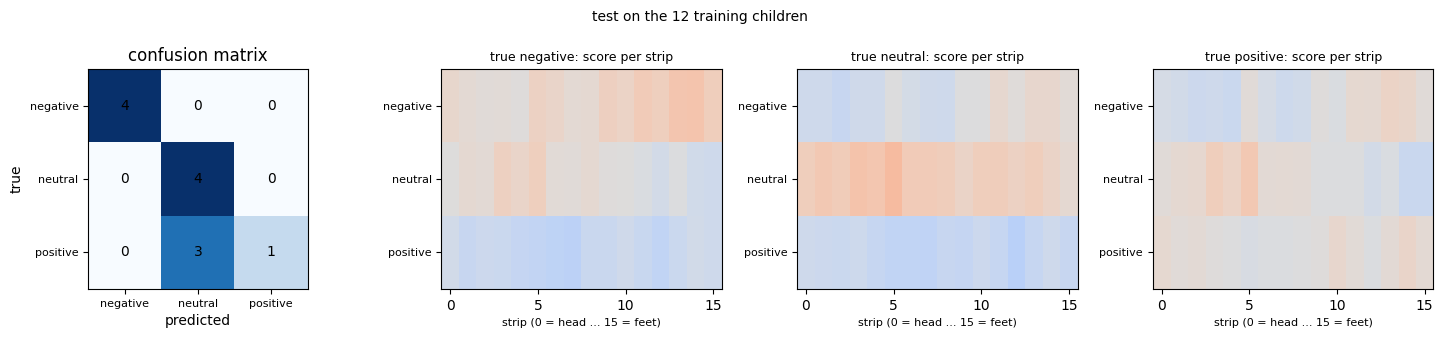

In [13]:
def predict(model, seq):
    x = torch.tensor(sil_transform(all_test_frames(seq)), dtype=torch.float32).unsqueeze(0).to(DEVICE)
    with torch.no_grad(), torch.autocast(device_type=DEVICE, enabled=USE_FP16):
        _, logits = model(x)
    mean_logits = logits.float().mean(-1)[0]
    prob = F.softmax(mean_logits * CE_SCALE, dim=-1).cpu().numpy()
    return mean_logits.argmax().item(), prob, logits.float()[0].cpu().numpy()


def compute_metrics(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    pos, neg = LABELS["positive"], LABELS["negative"]
    return {
        "accuracy": accuracy_score(y_true, y_pred) * 100,
        "precision": precision_score(y_true, y_pred, average="macro", zero_division=0) * 100,
        "recall": recall_score(y_true, y_pred, average="macro", zero_division=0) * 100,
        "f1": f1_score(y_true, y_pred, average="macro", zero_division=0) * 100,
        "sensitivity": (y_pred[y_true == pos] == pos).mean() * 100,
        "specificity": (y_pred[y_true == neg] == neg).mean() * 100,
    }


def evaluate(model, items, title, name):
    model.eval()
    y_true, y_pred, strip_logits = [], [], []
    for item in items:
        pred, prob, per_part = predict(model, item["seq"])
        y_true.append(item["label"])
        y_pred.append(pred)
        strip_logits.append(per_part)
        probs = "  ".join(f"{LABEL_NAMES[c][:3]} {prob[c]:.2f}" for c in range(3))
        mark = "" if pred == item["label"] else "  <- wrong"
        print(f"subject {item['subject']} | true {item['class']:>8} | predicted {LABEL_NAMES[pred]:>8} | {probs}{mark}")

    result = compute_metrics(y_true, y_pred)
    print()
    for key, value in result.items():
        print(f"{key:<12}{value:6.2f}%")

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
    strip_logits, y_true_arr = np.stack(strip_logits), np.array(y_true)
    n_panels = 1 if strip_logits.shape[-1] == 1 else 4
    fig, ax = plt.subplots(1, n_panels, figsize=(4.2 if n_panels == 1 else 15, 3.4), squeeze=False,
                           gridspec_kw={"width_ratios": [1.2] + [1] * (n_panels - 1)})
    ax = ax[0]
    ax[0].imshow(cm, cmap="Blues")
    for i in range(3):
        for j in range(3):
            ax[0].text(j, i, cm[i, j], ha="center", va="center")
    ax[0].set_xticks(range(3), LABEL_NAMES, fontsize=8)
    ax[0].set_yticks(range(3), LABEL_NAMES, fontsize=8)
    ax[0].set_xlabel("predicted")
    ax[0].set_ylabel("true")
    ax[0].set_title("confusion matrix")
    for a, c in zip(ax[1:], range(3)):
        a.imshow(strip_logits[y_true_arr == c].mean(0), cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
        a.set_yticks(range(3), LABEL_NAMES, fontsize=8)
        a.set_xlabel("strip (0 = head ... 15 = feet)", fontsize=8)
        a.set_title(f"true {LABEL_NAMES[c]}: score per strip", fontsize=9)
    fig.suptitle(title, fontsize=10)
    save_and_show(fig, name)
    return result


train_result = evaluate(model, train_data, "test on the 12 training children", "11_eval_train.png")

### My result
75.0%: negative and neutral perfect, but 3 of the 4 positives are called neutral (0.41-0.42 vs 0.37-0.41, very close). On the training children it's the weakest of the 3 ScoNets: the child triplet takes some of the 'effort' away from the classes.

subject 00536 | true negative | predicted  neutral | neg 0.35  neu 0.60  pos 0.05  <- wrong
subject 00914 | true negative | predicted  neutral | neg 0.17  neu 0.80  pos 0.03  <- wrong


subject 00937 | true negative | predicted  neutral | neg 0.34  neu 0.61  pos 0.04  <- wrong
subject 01243 | true negative | predicted  neutral | neg 0.30  neu 0.67  pos 0.03  <- wrong


subject 01340 | true  neutral | predicted  neutral | neg 0.20  neu 0.76  pos 0.04
subject 01384 | true  neutral | predicted  neutral | neg 0.33  neu 0.63  pos 0.04


subject 01387 | true  neutral | predicted  neutral | neg 0.25  neu 0.71  pos 0.04
subject 01486 | true  neutral | predicted  neutral | neg 0.30  neu 0.67  pos 0.03


subject 00172 | true positive | predicted  neutral | neg 0.26  neu 0.69  pos 0.04  <- wrong
subject 00237 | true positive | predicted  neutral | neg 0.14  neu 0.82  pos 0.03  <- wrong


subject 00282 | true positive | predicted  neutral | neg 0.22  neu 0.72  pos 0.06  <- wrong
subject 00473 | true positive | predicted  neutral | neg 0.31  neu 0.63  pos 0.07  <- wrong

accuracy     33.33%
precision    11.11%
recall       33.33%
f1           16.67%
sensitivity   0.00%
specificity   0.00%


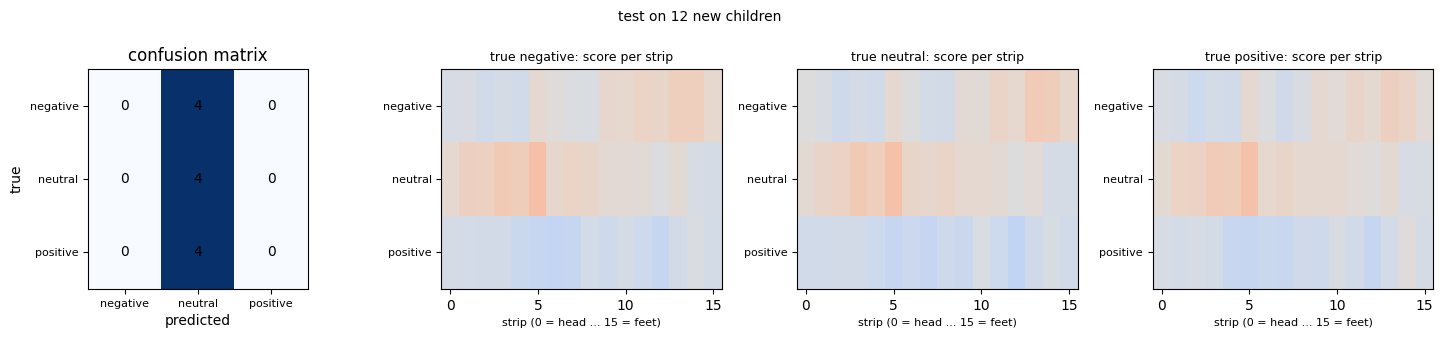

In [14]:
test_result = evaluate(model, test_data, "test on 12 new children", "11_eval_test.png")

### My result
33.3%: **every** test child is predicted neutral (0.60-0.82). The strip figure shows why: for all 3 true classes the neutral row is the warmest in strips ~1-8 (upper body), and the negative row only wins a bit in strips ~10-14 (legs). Extra check with the saved `model.pt`: with 30-frame clips like in training, ScoNet-MT gets 50% (predicts 3 / 3 / 6).

## 12 - Save the model and the numbers
- `model.pt`: the learned weights (`model.load_state_dict(torch.load(path))`)
- `results.json`: the metrics of this experiment, so I can put the 6 experiments side by side

In [15]:
torch.save(model.state_dict(), os.path.join(OUT_ROOT, "model.pt"))
results = {
    "experiment": EXPERIMENT,
    "version": 2,
    "train_children": train_pick,
    "test_children": test_pick,
    "iterations": TOTAL_ITER,
    "lr": LR,
    "skipped_fp16_steps": skipped,
    "train": train_result,
    "test": test_result,
    "paper_full_test_set": {"accuracy": 82.0, "sensitivity": 99.0, "specificity": 76.5},
}
with open(os.path.join(OUT_ROOT, "results.json"), "w") as f:
    json.dump(results, f, indent=2, default=float)
print("saved to", OUT_ROOT)

saved to C:\Users\ASUS\.vscode\OpenGait\self_learning\sconet_mt\output


## Summary: ScoNet-MT
.pkl `(frames, 64, 64)` -> cut + / 255 `(frames, 64, 44)` -> 30 random frames, 2 children per class x 2 copies `[12, 30, 64, 44]`
-> ResNet9 per frame -> max over frames `[12, 512, 16, 11]`
-> 16 strips `[12, 512, 16]` -> SeparateFCs embedding `[12, 256, 16]` -> BNNeck cosine logits `[12, 3, 16]`
-> loss = triplet (positives = same child) + cross entropy
-> SGD lr 0.001 + MultiStepLR -> test: all frames, mean over parts, argmax -> accuracy, macro P / R / F1, sensitivity, specificity

Paper (full 1:1:8 test set): accuracy 82.0%, sensitivity 99.0%, specificity 76.5%.

### My conclusion
The paper's best model (82.0%) is not the best in my mini version. The gait recognition part works (child blocks in the distance figure), but 12 children is way too few for MT. The paper's argument is that recognising many different people forces the network to learn general gait features. With 12 people there isn't much to generalise from, and all-frame testing puts every new child in neutral (50% with 30-frame clips).

All 6 on my 12 test children (train = the 12 training children):

| experiment | train acc | test acc | test sens | test spec | paper acc / sens / spec |
|---|---|---|---|---|---|
| CNN | 91.7 | 33.3 | 25.0 | 50.0 | 45.5 / 99.0 / 27.0 |
| CNN-Triplet | 100.0 | **66.7** | 75.0 | 75.0 | 56.3 / 77.0 / 85.0 |
| CNN-MT | 83.3 | 50.0 | 25.0 | 75.0 | 57.8 / 96.1 / 44.4 |
| ScoNet | 91.7 | 33.3 (all neutral) | 0.0 | 0.0 | 51.3 / 100.0 / 33.2 |
| ScoNet-Triplet | 100.0 | 33.3 (all neutral) | 0.0 | 0.0 | 61.2 / 100.0 / 46.6 |
| ScoNet-MT | 75.0 | 33.3 (all neutral) | 0.0 | 0.0 | 82.0 / 99.0 / 76.5 |

Extra check (done separately with the saved `model.pt`, not in the notebooks): testing with 30-frame clips like in training (5 clips averaged) instead of all 300 frames gives ScoNet 50.0%, ScoNet-MT 50.0% (both predict 3 / 3 / 6) and CNN-Triplet 75.0%. I only checked these 3.

What I learned from all 6 together:
- The 33.3% in version 1 was two different problems: the CNN ones were broken (loss `nan`, one class for everyone) and the ScoNet ones memorised the 12 training children. Now every model really trains.
- Without BNNeck the CNN is very fragile: it only survives with a small lr (0.001). That is exactly what the BNNeck does in ScoNet, it keeps the features and logits in a fixed range.
- On my mini set the ranking is **not** the paper's: CNN-Triplet is best and all ScoNets are at 33.3%. That doesn't mean the paper is wrong: I have 12 training children instead of 744, 300 iterations instead of 20000, 1 test child = 8.3 points, and the ScoNets have the 30-frames-train / 300-frames-test problem.
- The paper's test set is mostly positive (419 of 749), mine is 4 / 4 / 4, so my sensitivity and specificity come from only 4 children each.